# Completeness and added value vs Gaia (PLAN F12, James)

How many point sources get a proper motion from us, compared with Gaia, as a function of magnitude, and what we add:
(a) number counts per unit area vs r: Gaia sources with a Gaia PM, Gaia sources without one (two-parameter
solutions), and our PMs (all, clean, clean with sigma < 5 / 10 mas/yr); (b) for Gaia sources in our footprint, the
fraction that get a PM from us, vs Gaia G, and why the rest don't (not a point source in the Tractor model, flagged).

Data: combined v2 files of RA 000-063. `gaia-objects-<deg>` holds every Gaia source in the Tractor catalogue (any type,
any pm_flag); `pm-<deg>` every point source with a successful PM fit. Counts are accumulated per slice (16 workers).
Area: number of bricks x 0.0625 deg^2 (DR10 bricks are 0.25 deg on a side in Dec and equal-area in RA).

In [1]:
import os, sys
import numpy as np
import fitsio
import matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
OUT = '../writeup/plots/'
DEGREES = [f'{d:03d}' for d in range(64)]
RB = np.arange(14, 26.01, 0.25)      # r bins
GB = np.arange(12, 21.51, 0.25)      # Gaia G bins
BRICK_AREA = 0.0625                  # deg^2

def mag(f):
    with np.errstate(all='ignore'):
        return 22.5 - 2.5 * np.log10(f)

def sigma_pm(T):
    with np.errstate(all='ignore'):
        return np.sqrt((1 / T['pmra_no_plx_ivar'] + 1 / T['pmdec_no_plx_ivar']) / 2)

def count_slice(d):
    fp, fg, fb = (os.path.join(COMBINED_DIR, f'{k}-{d}.fits') for k in ('pm', 'gaia-objects', 'bricks'))
    if not os.path.exists(fp):
        return None
    out = {'n_bricks': fitsio.FITS(fb)[1].get_nrows()}
    P = fitsio.read(fp, columns=['flux_r', 'ref_cat', 'pmra_ivar', 'pm_quality', 'pmra_no_plx_ivar', 'pmdec_no_plx_ivar'])
    r, s, clean = mag(P['flux_r']), sigma_pm(P), P['pm_quality'] == 0
    gaia = np.char.strip(P['ref_cat'].astype(str)) == 'GE'
    h = lambda sel: np.histogram(r[sel], RB)[0]
    out['ours_all'] = h(np.ones(len(P), bool))
    out['ours_clean'] = h(clean)
    out['ours_clean_s10'] = h(clean & (s < 10))
    out['ours_clean_s5'] = h(clean & (s < 5))
    out['ours_clean_nongaia_s10'] = h(clean & (s < 10) & ~gaia)
    # Gaia sources: per-source rows, de-duplicated over all slices afterwards. Tractor catalogues also contain the
    # sources in the overlap strips with neighbouring bricks (brick_primary = False); forced photometry measures only
    # primary sources, so these duplicates never get a fit. gaia-objects keeps them -> count each Gaia source once.
    G = fitsio.read(fg, columns=['ref_id', 'type', 'flux_r', 'gaia_phot_g_mean_mag', 'pmra_ivar', 'pm_flag', 'pm_quality',
                                 'pmra_no_plx_ivar', 'pmdec_no_plx_ivar'])
    out['g_ref_id'] = G['ref_id'].astype(np.int64)
    out['g_r'] = mag(G['flux_r']).astype(np.float32)
    out['g_G'] = G['gaia_phot_g_mean_mag'].astype(np.float32)
    out['g_sigma'] = sigma_pm(G).astype(np.float32)
    out['g_has_gpm'] = G['pmra_ivar'] > 0
    out['g_psf'] = np.char.strip(G['type'].astype(str)) == 'PSF'
    out['g_ours'] = G['pm_flag'] == 1
    out['g_clean'] = out['g_ours'] & (G['pm_quality'] == 0)
    out['g_q'] = G['pm_quality'].astype(np.int16)
    return out

with ProcessPoolExecutor(16, mp_context=mp.get_context('fork')) as ex:
    parts = [p for p in ex.map(count_slice, DEGREES) if p is not None]
C = {k: (np.concatenate([p[k] for p in parts]) if k.startswith('g_') else sum(p[k] for p in parts)) for k in parts[0]}
AREA = C['n_bricks'] * BRICK_AREA
# one row per Gaia source: prefer a row we fitted (clean first), then a point-source row
n_rows = len(C['g_ref_id'])
order = np.lexsort((~C['g_psf'], ~C['g_ours'], ~C['g_clean'], C['g_ref_id']))
first = order[np.r_[True, C['g_ref_id'][order][1:] != C['g_ref_id'][order][:-1]]]
for k in [k for k in C if k.startswith('g_')]:
    C[k] = C[k][first]
print(f"Gaia rows {n_rows:,} -> {len(first):,} unique Gaia sources ({1 - len(first) / n_rows:.1%} duplicates in brick overlaps)")
hr = lambda sel: np.histogram(C['g_r'][sel], RB)[0]
hg = lambda sel: np.histogram(C['g_G'][sel], GB)[0]
gp, ok, oc, ps_ = C['g_has_gpm'], C['g_ours'], C['g_clean'], C['g_psf']
C['gaia_pm_r'], C['gaia_nopm_r'], C['gaia_nopm_ours_clean_r'] = hr(gp), hr(~gp), hr(~gp & oc)
for name, sel in [('all', np.ones(len(gp), bool)), ('psf', ps_), ('ours', ok), ('ours_clean', oc)]:
    C[f'G_pm_{name}'], C[f'G_nopm_{name}'] = hg(gp & sel), hg(~gp & sel)
C['nopm_clean_sigma'], C['nopm_clean_G'] = C['g_sigma'][~gp & oc], C['g_G'][~gp & oc]
print(f"{len(parts)} slices, {C['n_bricks']:,} bricks, {AREA:,.0f} deg^2")

Gaia rows 24,184,320 -> 22,785,256 unique Gaia sources (5.8% duplicates in brick overlaps)


64 slices, 81,491 bricks, 5,093 deg^2


In [2]:
rc = 0.5 * (RB[1:] + RB[:-1]); gc = 0.5 * (GB[1:] + GB[:-1])
tot = lambda k, lo=-99, hi=99: int(C[k][(rc > lo) & (rc < hi)].sum())
print('point sources with PMs (millions):')
for k in ['ours_all', 'ours_clean', 'ours_clean_s10', 'ours_clean_s5', 'ours_clean_nongaia_s10', 'gaia_pm_r', 'gaia_nopm_r', 'gaia_nopm_ours_clean_r']:
    print(f'  {k:26s} all r: {tot(k)/1e6:7.2f}   r > 21: {tot(k, 21)/1e6:7.2f}')
for name in ['pm', 'nopm']:
    a = C[f'G_{name}_all'].sum()
    print(f"Gaia sources {'with' if name == 'pm' else 'without'} a Gaia PM: {a:,}; point sources {C[f'G_{name}_psf'].sum()/a:.1%}, "
          f"with our PM {C[f'G_{name}_ours'].sum()/a:.1%}, clean {C[f'G_{name}_ours_clean'].sum()/a:.1%}")
s, g = C['nopm_clean_sigma'], C['nopm_clean_G']
print(f'Gaia sources without a Gaia PM but a clean PM from us: {len(s):,}; median sigma {np.median(s):.2f} mas/yr; '
      f'sigma < 5: {np.mean(s < 5):.1%}; their G: median {np.median(g):.2f}, G < 20: {np.mean(g < 20):.1%}')
# where we overtake Gaia: r at which our clean sigma < 10 counts exceed Gaia-with-PM counts
ex = rc[(C['ours_clean_s10'] > C['gaia_pm_r']) & (rc > 18)]
print('our clean sigma<10 counts exceed Gaia-with-PM counts from r =', ex.min() if len(ex) else None)

point sources with PMs (millions):
  ours_all                   all r:  251.41   r > 21:  233.71
  ours_clean                 all r:  194.20   r > 21:  183.13
  ours_clean_s10             all r:   28.06   r > 21:   17.01
  ours_clean_s5              all r:   19.32   r > 21:    8.52
  ours_clean_nongaia_s10     all r:   15.96   r > 21:   15.85
  gaia_pm_r                  all r:   17.32   r > 21:    0.53
  gaia_nopm_r                all r:    3.79   r > 21:    1.08
  gaia_nopm_ours_clean_r     all r:    1.43   r > 21:    0.77
Gaia sources with a Gaia PM: 18,589,017; point sources 98.6%, with our PM 94.6%, clean 57.7%
Gaia sources without a Gaia PM: 3,574,229; point sources 65.9%, with our PM 62.1%, clean 39.9%
Gaia sources without a Gaia PM but a clean PM from us: 1,435,462; median sigma 1.84 mas/yr; sigma < 5: 90.8%; their G: median 20.97, G < 20: 3.6%
our clean sigma<10 counts exceed Gaia-with-PM counts from r = 20.875


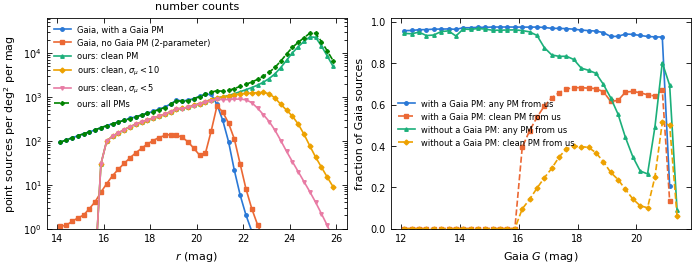

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(ps.PAGE, 2.7), layout='constrained')
dr = RB[1] - RB[0]
lines = [('gaia_pm_r', 'Gaia, with a Gaia PM', '-'), ('gaia_nopm_r', 'Gaia, no Gaia PM (2-parameter)', '-'),
         ('ours_clean', 'ours: clean PM', '-'), ('ours_clean_s10', r'ours: clean, $\sigma_\mu < 10$', '-'),
         ('ours_clean_s5', r'ours: clean, $\sigma_\mu < 5$', '-'), ('ours_all', 'ours: all PMs', '--')]
for k, (key, lab, ls) in enumerate(lines):
    ax[0].semilogy(rc, C[key] / AREA / dr, ls=ls, marker=ps.MARKERS[k], ms=2.5, color=ps.SERIES[k], label=lab)
ax[0].set_xlabel('$r$ (mag)'); ax[0].set_ylabel(r'point sources per deg$^2$ per mag'); ax[0].set_ylim(1, None)
ax[0].legend(fontsize=6, loc='upper left')
ax[0].set_title('number counts')
for k, (name, lab) in enumerate([('pm', 'with a Gaia PM'), ('nopm', 'without a Gaia PM')]):
    a = np.maximum(C[f'G_{name}_all'], 1)
    ok = C[f'G_{name}_all'] >= 200
    ax[1].plot(gc[ok], (C[f'G_{name}_ours'] / a)[ok], ps.MARKERS[2 * k] + '-', ms=2.5, color=ps.SERIES[2 * k], label=f'{lab}: any PM from us')
    ax[1].plot(gc[ok], (C[f'G_{name}_ours_clean'] / a)[ok], ps.MARKERS[2 * k + 1] + '--', ms=2.5, color=ps.SERIES[2 * k + 1], label=f'{lab}: clean PM from us')
ax[1].set_xlabel('Gaia $G$ (mag)'); ax[1].set_ylabel('fraction of Gaia sources'); ax[1].set_ylim(0, 1.02)
ax[1].legend(fontsize=6, loc='center left')   # empty region at bright G, below the curves; ax[1].set_title('Gaia sources with a PM from us')
plt.savefig(OUT + 'completeness_vs_gaia.pdf')

In [4]:
# why Gaia sources (with a Gaia PM) get no clean PM from us, by G: not a point source, flagged, or no fit
print(f"{'G':>5s} {'N':>9s} {'not PSF':>8s} {'PSF, no fit':>11s} {'flagged':>8s} {'clean':>7s}")   # unique Gaia sources
for i in range(0, len(gc), 2):
    a = C['G_pm_all'][i:i+2].sum()
    if a < 1000: continue
    psf, ours, cl = C['G_pm_psf'][i:i+2].sum(), C['G_pm_ours'][i:i+2].sum(), C['G_pm_ours_clean'][i:i+2].sum()
    print(f'{GB[i]:5.1f} {a:9,d} {1 - psf/a:8.1%} {(psf - ours)/a:11.1%} {(ours - cl)/a:8.1%} {cl/a:7.1%}')
# which flags, for Gaia sources with a Gaia PM that we fit, in two magnitude ranges (bits can overlap)
BITS = {1: 'FEW_EPOCHS', 2: 'SHORT_BASELINE', 4: 'NO_COLOUR', 8: 'BRIGHT', 16: 'SATURATED', 32: 'FIT_FAILED', 64: 'BAD_EPOCHS'}
for lo, hi in [(12, 16), (17, 20.5)]:
    sel = C['g_has_gpm'] & C['g_ours'] & (C['g_G'] >= lo) & (C['g_G'] < hi)
    q = C['g_q'][sel].astype(int)
    print(f'G {lo}-{hi}: {sel.sum():,} fitted; flagged {np.mean(q != 0):.1%}; ' + ', '.join(f'{n} {np.mean(q & b > 0):.1%}' for b, n in BITS.items()))

    G         N  not PSF PSF, no fit  flagged   clean
 12.0    70,995     0.1%        4.1%    95.8%    0.0%
 12.5    98,263     0.1%        3.7%    96.2%    0.0%
 13.0   132,885     0.1%        3.4%    96.5%    0.0%
 13.5   178,169     0.5%        3.1%    96.4%    0.0%
 14.0   232,719     0.2%        2.7%    97.1%    0.0%
 14.5   299,967     0.1%        2.5%    97.3%    0.0%
 15.0   381,410     0.1%        2.4%    97.5%    0.0%
 15.5   478,291     0.2%        2.4%    97.5%    0.0%
 16.0   597,844     0.2%        2.4%    53.9%   43.5%
 16.5   734,957     0.3%        2.3%    40.6%   56.7%
 17.0   899,697     0.7%        2.5%    32.3%   64.6%
 17.5 1,094,231     0.7%        2.8%    28.7%   67.9%
 18.0 1,341,425     0.8%        3.3%    27.8%   68.0%
 18.5 1,693,667     0.9%        4.0%    28.2%   66.9%
 19.0 2,340,004     1.1%        6.0%    31.2%   61.8%
 19.5 2,459,154     1.7%        4.3%    27.8%   66.2%
 20.0 3,032,549     2.4%        4.5%    28.0%   65.2%
 20.5 2,517,225     2.9%    

G 17-20.5: 12,135,878 fitted; flagged 30.6%; FEW_EPOCHS 14.0%, SHORT_BASELINE 17.3%, NO_COLOUR 7.1%, BRIGHT 5.9%, SATURATED 1.0%, FIT_FAILED 0.0%, BAD_EPOCHS 4.7%
